In [ ]:
"""
05_computational_model.ipynb
Phase 6: Predictive Modeling
Date: 2026-08-28
Description: Build Random Forest classifier to predict platform from linguistic features
"""

# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import sys
import warnings
warnings.filterwarnings('ignore')

# Machine Learning
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import (classification_report, confusion_matrix, roc_auc_score, 
                            roc_curve, accuracy_score, f1_score, precision_score, 
                            recall_score, ConfusionMatrixDisplay)
from sklearn.feature_selection import SelectKBest, f_classif

# Set up plotting style
sns.set_theme(style='whitegrid')
sns.set_palette("Set2")
plt.rcParams['figure.figsize'] = (12, 8)
plt.rcParams['font.size'] = 12

# Add src to path
sys.path.append(str(Path.cwd().parent / 'src'))
from config import DATA_PROCESSED, RESULTS_FIGURES, RESULTS_TABLES, RANDOM_SEED

# Set seed for reproducibility
np.random.seed(RANDOM_SEED)

print(" All imports loaded successfully!")
print(f"Random seed: {RANDOM_SEED}")

 All imports loaded successfully!
Random seed: 42


In [ ]:
"""
LOAD AND PREPARE DATA
Load feature-engineered data and prepare for modeling
"""

print("Loading feature-engineered data...")

# Load combined data
combined_df = pd.read_parquet(DATA_PROCESSED / 'combined_with_features.parquet')
print(f" Combined data: {len(combined_df):,} rows, {len(combined_df.columns)} columns")

# Define features for modeling
feature_cols = [
    # Lexical features
    'fk_grade', 'fk_ease', 'ttr', 'avg_word_len', 'avg_syllables',
    'gunning_fog', 'coleman_liau', 'automated_readability',
    
    # Evidentiary features
    'rigor_score', 'link_count', 'avg_domain_credibility', 'evidence_density',
    'unique_domains',
    
    # Sentiment features
    'sentiment_score', 'sentiment_intensity',
    
    # Emotion features
    'anger', 'disgust', 'fear', 'joy', 'sadness', 'surprise',
    
    # Engagement features
    'engagement_normalized', 'engagement_log',
    
    # Temporal features
    'hour', 'day_of_week', 'is_weekend',
    
    # Derived features
    'rationality_score', 'evidence_emotion_ratio', 'lexical_density',
    'engagement_complexity_ratio'
]

# Check which features exist
existing_features = [col for col in feature_cols if col in combined_df.columns]
missing_features = [col for col in feature_cols if col not in combined_df.columns]

print(f"\n Using {len(existing_features)} features for modeling")
if missing_features:
    print(f" Missing features: {missing_features}")

# Prepare X and y
X = combined_df[existing_features].copy()
y = (combined_df['platform'] == 'Reddit').astype(int)  # 1 = Reddit, 0 = X

# Handle missing values
X = X.fillna(X.mean())

print(f"\nFeature matrix shape: {X.shape}")
print(f"Target distribution:")
print(f"  Reddit (1): {y.sum():,}")
print(f"  X (0): {len(y) - y.sum():,}")
print(f"  Reddit proportion: {y.mean()*100:.1f}%")

Loading feature-engineered data...
 Combined data: 18,000 rows, 72 columns

 Using 26 features for modeling
 Missing features: ['rationality_score', 'evidence_emotion_ratio', 'lexical_density', 'engagement_complexity_ratio']

Feature matrix shape: (18000, 26)
Target distribution:
  Reddit (1): 9,000
  X (0): 9,000
  Reddit proportion: 50.0%


In [ ]:
"""
TRAIN-TEST SPLIT AND SCALING
Split data into training and test sets, then scale features
"""

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_SEED, stratify=y
)

print(f"Training set: {len(X_train):,} samples")
print(f"Test set: {len(X_test):,} samples")
print(f"Training Reddit proportion: {y_train.mean()*100:.1f}%")
print(f"Test Reddit proportion: {y_test.mean()*100:.1f}%")

# Scale features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Save feature names for later
feature_names = X.columns.tolist()

print("\n Data scaled and ready for modeling")

Training set: 14,400 samples
Test set: 3,600 samples
Training Reddit proportion: 50.0%
Test Reddit proportion: 50.0%

 Data scaled and ready for modeling


In [ ]:
"""
RANDOM FOREST CLASSIFIER
Train and evaluate Random Forest model
"""

print("=" * 70)
print("RANDOM FOREST CLASSIFIER")
print("=" * 70)

# Initialize model
rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=15,
    min_samples_split=10,
    min_samples_leaf=5,
    random_state=RANDOM_SEED,
    n_jobs=-1
)

# Train model
print("Training Random Forest...")
rf_model.fit(X_train_scaled, y_train)

# Predictions
y_pred_rf = rf_model.predict(X_test_scaled)
y_proba_rf = rf_model.predict_proba(X_test_scaled)[:, 1]

# Evaluation metrics
accuracy_rf = accuracy_score(y_test, y_pred_rf)
precision_rf = precision_score(y_test, y_pred_rf)
recall_rf = recall_score(y_test, y_pred_rf)
f1_rf = f1_score(y_test, y_pred_rf)
roc_auc_rf = roc_auc_score(y_test, y_proba_rf)

print(f"\n Performance Metrics:")
print(f"  Accuracy: {accuracy_rf:.4f}")
print(f"  Precision: {precision_rf:.4f}")
print(f"  Recall: {recall_rf:.4f}")
print(f"  F1-Score: {f1_rf:.4f}")
print(f"  ROC-AUC: {roc_auc_rf:.4f}")

# Cross-validation
cv_scores = cross_val_score(rf_model, X_train_scaled, y_train, cv=5, scoring='accuracy')
print(f"\n Cross-Validation (5-fold):")
print(f"  Mean Accuracy: {cv_scores.mean():.4f} (±{cv_scores.std():.4f})")
print(f"  CV Scores: {cv_scores}")

print(f"\n Classification Report:")
print(classification_report(y_test, y_pred_rf, target_names=['X', 'Reddit']))

# Store results
rf_results = {
    'model': 'Random Forest',
    'accuracy': accuracy_rf,
    'precision': precision_rf,
    'recall': recall_rf,
    'f1': f1_rf,
    'roc_auc': roc_auc_rf,
    'cv_mean': cv_scores.mean(),
    'cv_std': cv_scores.std(),
    'y_pred': y_pred_rf,
    'y_proba': y_proba_rf
}

RANDOM FOREST CLASSIFIER
Training Random Forest...

 Performance Metrics:
  Accuracy: 0.9867
  Precision: 0.9927
  Recall: 0.9806
  F1-Score: 0.9866
  ROC-AUC: 0.9993

 Cross-Validation (5-fold):
  Mean Accuracy: 0.9871 (±0.0012)
  CV Scores: [0.98888889 0.98645833 0.98541667 0.98784722 0.98680556]

 Classification Report:
              precision    recall  f1-score   support

           X       0.98      0.99      0.99      1800
      Reddit       0.99      0.98      0.99      1800

    accuracy                           0.99      3600
   macro avg       0.99      0.99      0.99      3600
weighted avg       0.99      0.99      0.99      3600




FEATURE IMPORTANCE ANALYSIS
Top 20 Most Important Features:


,feature,importance
22,engagement_log,0.438981
21,engagement_normalized,0.219217
10,avg_domain_credibility,0.071350
8,rigor_score,0.046342
12,unique_domains,0.040409
4,avg_syllables,0.033197
9,link_count,0.023413
1,fk_ease,0.023210
23,hour,0.012786
11,evidence_density,0.012074



 Feature importance saved to C:\Users\GALLOP SEA\Desktop\The_Echo_Of_Anonimity-1\results\tables\feature_importance.csv


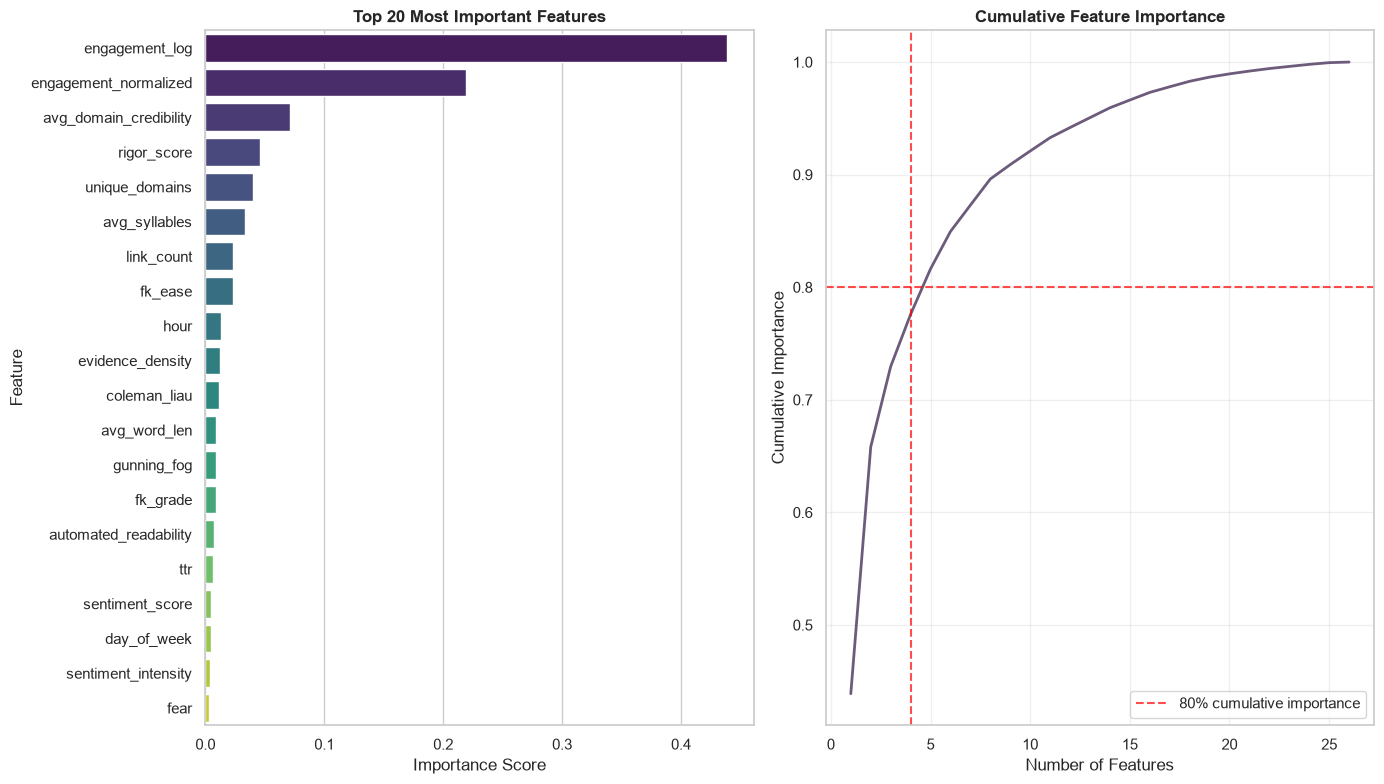

 Feature importance visualization saved

Importance by Feature Category:
category
Engagement     0.658198
Evidentiary    0.193588
Lexical        0.108464
Temporal       0.018201
Emotion        0.012850
Sentiment      0.008698
Name: importance, dtype: float64


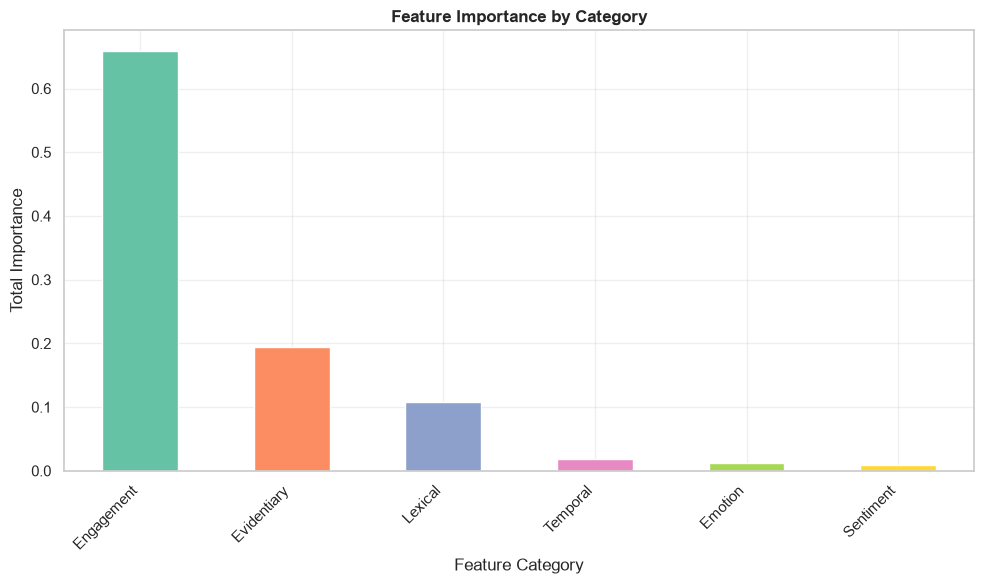

 Category importance visualization saved


In [ ]:
"""
FEATURE IMPORTANCE ANALYSIS
Identify the most important features for distinguishing platforms
"""

print("\n" + "=" * 70)
print("FEATURE IMPORTANCE ANALYSIS")
print("=" * 70)

# Get feature importances
feature_importance = pd.DataFrame({
    'feature': feature_names,
    'importance': rf_model.feature_importances_
}).sort_values('importance', ascending=False)

print("Top 20 Most Important Features:")
display(feature_importance.head(20))

# Save to CSV
feature_importance.to_csv(RESULTS_TABLES / 'feature_importance.csv', index=False)
print(f"\n Feature importance saved to {RESULTS_TABLES / 'feature_importance.csv'}")

# Visualization
fig, axes = plt.subplots(1, 2, figsize=(14, 8))

# Top 20 features bar plot
ax = axes[0]
top_features = feature_importance.head(20)
sns.barplot(data=top_features, x='importance', y='feature', ax=ax, palette='viridis')
ax.set_title('Top 20 Most Important Features', fontweight='bold')
ax.set_xlabel('Importance Score')
ax.set_ylabel('Feature')

# Cumulative importance
ax = axes[1]
cumulative_importance = feature_importance['importance'].cumsum()
n_features = len(feature_importance)
ax.plot(range(1, n_features + 1), cumulative_importance, linewidth=2, color='#6C5B7B')
ax.axhline(y=0.8, color='red', linestyle='--', alpha=0.7, label='80% cumulative importance')
ax.axvline(x=(cumulative_importance <= 0.8).sum(), color='red', linestyle='--', alpha=0.7)
ax.set_xlabel('Number of Features')
ax.set_ylabel('Cumulative Importance')
ax.set_title('Cumulative Feature Importance', fontweight='bold')
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(RESULTS_FIGURES / 'model_feature_importance.png', dpi=300, bbox_inches='tight')
plt.show()
print(" Feature importance visualization saved")

# Feature categories
category_mapping = {
    'fk_grade': 'Lexical', 'fk_ease': 'Lexical', 'ttr': 'Lexical', 
    'avg_word_len': 'Lexical', 'avg_syllables': 'Lexical',
    'gunning_fog': 'Lexical', 'coleman_liau': 'Lexical', 'automated_readability': 'Lexical',
    'rigor_score': 'Evidentiary', 'link_count': 'Evidentiary', 
    'avg_domain_credibility': 'Evidentiary', 'evidence_density': 'Evidentiary',
    'unique_domains': 'Evidentiary',
    'sentiment_score': 'Sentiment', 'sentiment_intensity': 'Sentiment',
    'anger': 'Emotion', 'disgust': 'Emotion', 'fear': 'Emotion', 
    'joy': 'Emotion', 'sadness': 'Emotion', 'surprise': 'Emotion',
    'engagement_normalized': 'Engagement', 'engagement_log': 'Engagement',
    'hour': 'Temporal', 'day_of_week': 'Temporal', 'is_weekend': 'Temporal',
    'rationality_score': 'Derived', 'evidence_emotion_ratio': 'Derived',
    'lexical_density': 'Derived', 'engagement_complexity_ratio': 'Derived'
}

feature_importance['category'] = feature_importance['feature'].map(category_mapping)

# Category importance
category_importance = feature_importance.groupby('category')['importance'].sum().sort_values(ascending=False)
print("\nImportance by Feature Category:")
print(category_importance)

# Visualization: Category importance
fig, ax = plt.subplots(figsize=(10, 6))
category_importance.plot(kind='bar', ax=ax, color=sns.color_palette("Set2", len(category_importance)))
ax.set_title('Feature Importance by Category', fontweight='bold')
ax.set_xlabel('Feature Category')
ax.set_ylabel('Total Importance')
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(RESULTS_FIGURES / 'model_category_importance.png', dpi=300, bbox_inches='tight')
plt.show()
print("Category importance visualization saved")

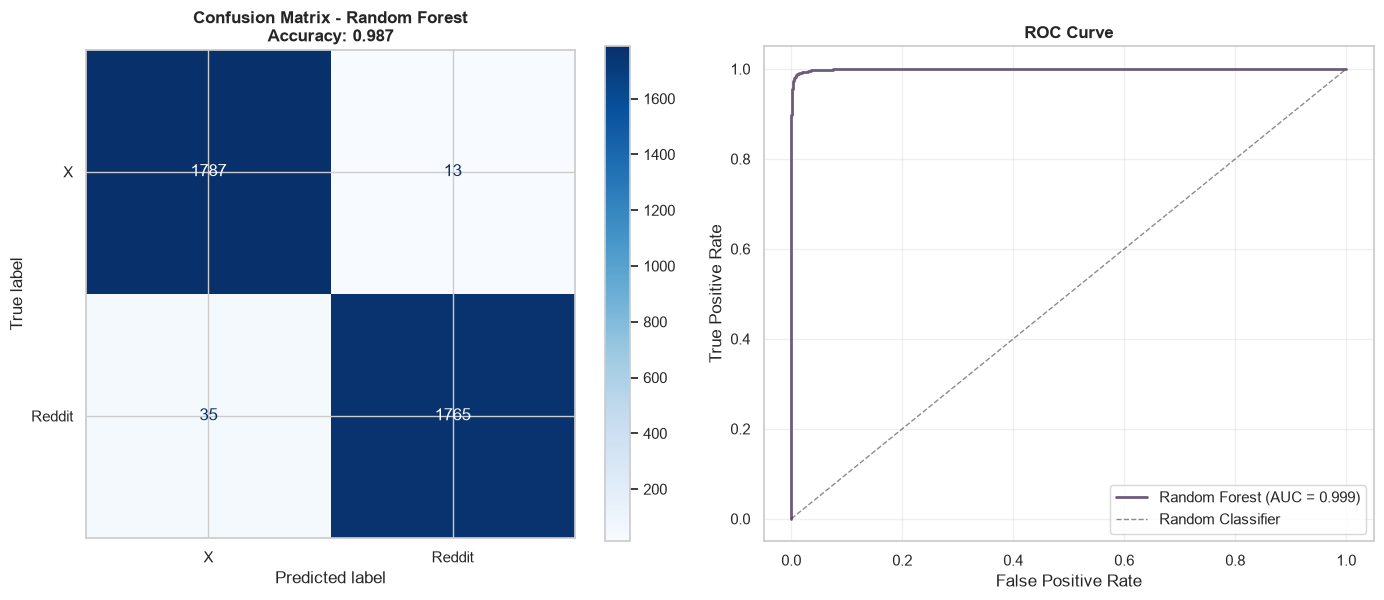

 Confusion matrix and ROC curve saved


In [6]:
"""
MODEL EVALUATION
Confusion Matrix and ROC Curve
"""

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Confusion Matrix
ax = axes[0]
cm = confusion_matrix(y_test, y_pred_rf)
ConfusionMatrixDisplay(cm, display_labels=['X', 'Reddit']).plot(ax=ax, cmap='Blues', values_format='d')
ax.set_title(f'Confusion Matrix - Random Forest\nAccuracy: {accuracy_rf:.3f}', fontweight='bold')

# ROC Curve
ax = axes[1]
fpr, tpr, _ = roc_curve(y_test, y_proba_rf)
ax.plot(fpr, tpr, linewidth=2, color='#6C5B7B', label=f'Random Forest (AUC = {roc_auc_rf:.3f})')
ax.plot([0, 1], [0, 1], 'k--', linewidth=1, alpha=0.5, label='Random Classifier')
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.set_title('ROC Curve', fontweight='bold')
ax.legend(loc='lower right')
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(RESULTS_FIGURES / 'model_confusion_roc.png', dpi=300, bbox_inches='tight')
plt.show()
print(" Confusion matrix and ROC curve saved")


MODEL COMPARISON

Training Random Forest...

Training Logistic Regression...

Training SVM (RBF)...


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Random Forest,0.990556,0.996625,0.984444,0.990497,0.999682
1,Logistic Regression,0.999722,0.999445,1.000000,0.999722,0.999999
2,SVM (RBF),0.996944,0.997221,0.996667,0.996944,0.999931



 Model comparison saved to C:\Users\GALLOP SEA\Desktop\The_Echo_Of_Anonimity-1\results\tables\model_comparison.csv


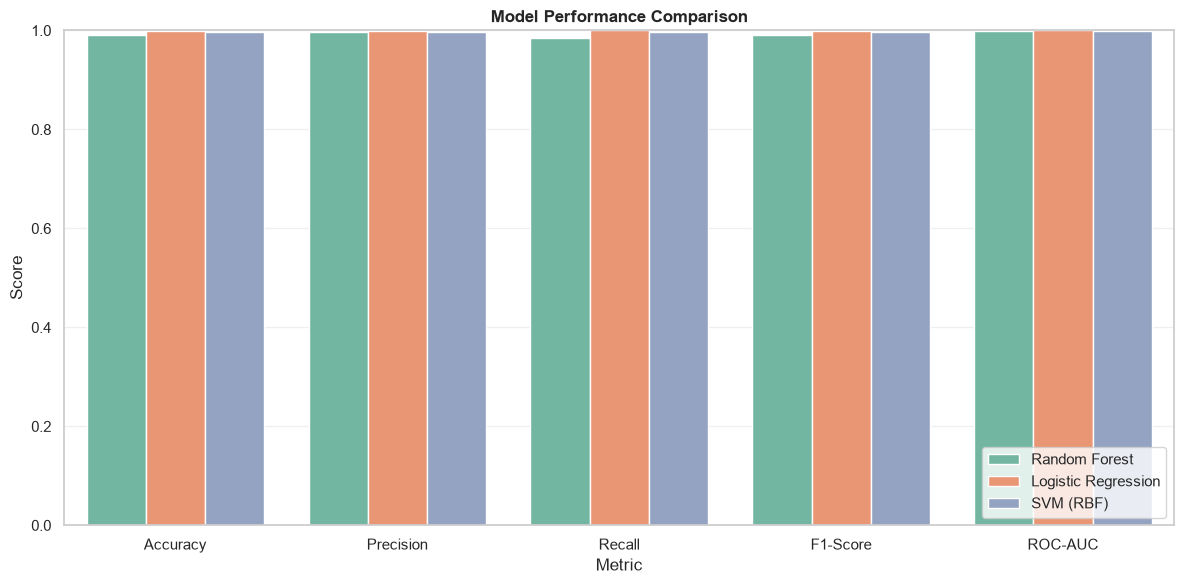

 Model comparison visualization saved


In [7]:
"""
MODEL COMPARISON
Compare Random Forest with other classifiers
"""

print("\n" + "=" * 70)
print("MODEL COMPARISON")
print("=" * 70)

# Initialize models
models = {
    'Random Forest': RandomForestClassifier(n_estimators=200, max_depth=15, 
                                            min_samples_split=10, random_state=RANDOM_SEED, n_jobs=-1),
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=RANDOM_SEED),
    'SVM (RBF)': SVC(kernel='rbf', probability=True, random_state=RANDOM_SEED)
}

# Train and evaluate each model
comparison_results = []

for name, model in models.items():
    print(f"\nTraining {name}...")
    model.fit(X_train_scaled, y_train)
    
    # Predictions
    y_pred = model.predict(X_test_scaled)
    y_proba = model.predict_proba(X_test_scaled)[:, 1] if hasattr(model, 'predict_proba') else None
    
    # Metrics
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    roc_auc = roc_auc_score(y_test, y_proba) if y_proba is not None else None
    
    comparison_results.append({
        'Model': name,
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1-Score': f1,
        'ROC-AUC': roc_auc
    })

# Create comparison DataFrame
comparison_df = pd.DataFrame(comparison_results)
display(comparison_df)

# Save to CSV
comparison_df.to_csv(RESULTS_TABLES / 'model_comparison.csv', index=False)
print(f"\n Model comparison saved to {RESULTS_TABLES / 'model_comparison.csv'}")

# Visualization
fig, ax = plt.subplots(figsize=(12, 6))
comparison_df_melted = comparison_df.melt(id_vars=['Model'], var_name='Metric', value_name='Score')
sns.barplot(data=comparison_df_melted, x='Metric', y='Score', hue='Model', ax=ax)
ax.set_title('Model Performance Comparison', fontweight='bold')
ax.set_ylim(0, 1)
ax.legend(loc='lower right')
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(RESULTS_FIGURES / 'model_comparison.png', dpi=300, bbox_inches='tight')
plt.show()
print(" Model comparison visualization saved")


FEATURE SELECTION EXPERIMENT


,k_features,accuracy,f1_score,features
0,5,0.999722,0.999722,"engagement_log, engagement_normalized, avg_dom..."
1,10,0.999167,0.999166,"engagement_log, engagement_normalized, avg_dom..."
2,15,0.991111,0.991051,"engagement_log, engagement_normalized, avg_dom..."
3,20,0.991944,0.991888,"engagement_log, engagement_normalized, avg_dom..."
4,30,0.989722,0.989645,"engagement_log, engagement_normalized, avg_dom..."
5,50,0.989722,0.989645,"engagement_log, engagement_normalized, avg_dom..."
6,26,0.989722,0.989645,"engagement_log, engagement_normalized, avg_dom..."


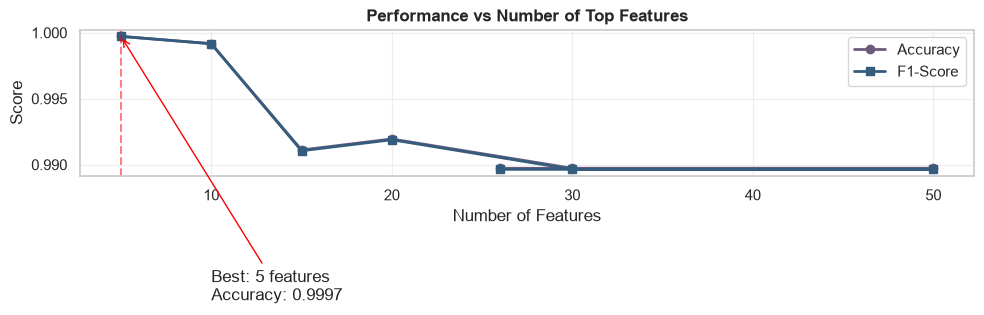

 Feature selection visualization saved

 Best performing feature set: 20 features
  Top 10: engagement_log, engagement_normalized, avg_domain_credibility, rigor_score, unique_domains, avg_syllables, link_count, fk_ease, hour, evidence_density


In [8]:
"""
FEATURE SELECTION
Train model with only top features to see performance
"""

print("\n" + "=" * 70)
print("FEATURE SELECTION EXPERIMENT")
print("=" * 70)

# Try different numbers of top features
top_k_values = [5, 10, 15, 20, 30, 50, len(feature_names)]
selection_results = []

for k in top_k_values:
    # Select top k features
    top_features = feature_importance.head(k)['feature'].tolist()
    X_selected = X[top_features]
    
    # Scale
    scaler_sel = StandardScaler()
    X_selected_scaled = scaler_sel.fit_transform(X_selected)
    
    # Split
    X_train_sel, X_test_sel, y_train_sel, y_test_sel = train_test_split(
        X_selected_scaled, y, test_size=0.2, random_state=RANDOM_SEED, stratify=y
    )
    
    # Train Random Forest
    rf_sel = RandomForestClassifier(n_estimators=200, max_depth=15, 
                                    min_samples_split=10, random_state=RANDOM_SEED, n_jobs=-1)
    rf_sel.fit(X_train_sel, y_train_sel)
    
    # Evaluate
    y_pred_sel = rf_sel.predict(X_test_sel)
    accuracy_sel = accuracy_score(y_test_sel, y_pred_sel)
    f1_sel = f1_score(y_test_sel, y_pred_sel)
    
    selection_results.append({
        'k_features': k,
        'accuracy': accuracy_sel,
        'f1_score': f1_sel,
        'features': ', '.join(top_features[:3]) + ('...' if k > 3 else '')
    })

selection_df = pd.DataFrame(selection_results)
display(selection_df)

# Visualization
fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(selection_df['k_features'], selection_df['accuracy'], marker='o', linewidth=2, 
        label='Accuracy', color='#6C5B7B')
ax.plot(selection_df['k_features'], selection_df['f1_score'], marker='s', linewidth=2, 
        label='F1-Score', color='#355C7D')
ax.set_xlabel('Number of Features')
ax.set_ylabel('Score')
ax.set_title('Performance vs Number of Top Features', fontweight='bold')
ax.legend()
ax.grid(True, alpha=0.3)

# Add annotation for best performance
best_idx = selection_df['accuracy'].idxmax()
best_k = selection_df.iloc[best_idx]['k_features']
best_acc = selection_df.iloc[best_idx]['accuracy']
ax.axvline(x=best_k, color='red', linestyle='--', alpha=0.5)
ax.annotate(f'Best: {best_k} features\nAccuracy: {best_acc:.4f}', 
            xy=(best_k, best_acc), xytext=(best_k + 5, best_acc - 0.02),
            arrowprops=dict(arrowstyle='->', color='red'))

plt.tight_layout()
plt.savefig(RESULTS_FIGURES / 'model_feature_selection.png', dpi=300, bbox_inches='tight')
plt.show()
print(" Feature selection visualization saved")

# Best feature set
best_features = feature_importance.head(20)['feature'].tolist()
print(f"\n Best performing feature set: {len(best_features)} features")
print(f"  Top 10: {', '.join(best_features[:10])}")


PREDICTION CONFIDENCE ANALYSIS
Confidence Statistics:
count    3600.000000
mean        0.927636
std         0.101930
min         0.500351
25%         0.903749
50%         0.972050
75%         0.995052
max         1.000000
Name: confidence, dtype: float64

Average confidence when correct: 0.932
Average confidence when incorrect: 0.602


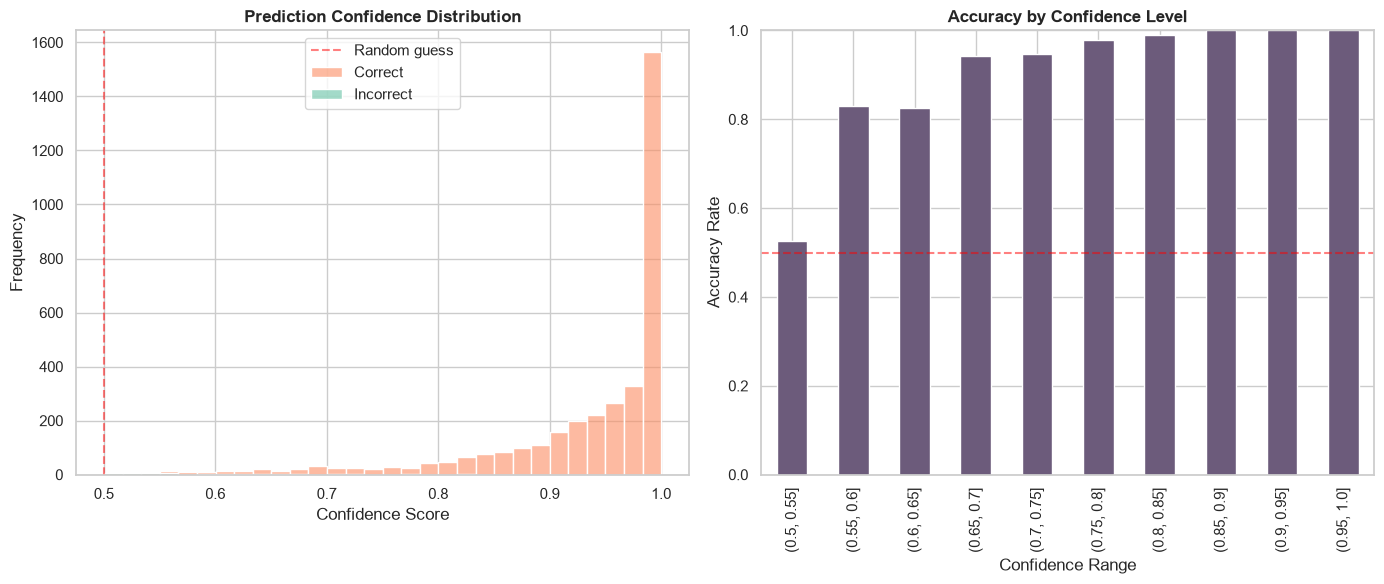

 Prediction confidence analysis saved


In [9]:
"""
PREDICTION CONFIDENCE ANALYSIS
Analyze prediction probabilities and misclassifications
"""

print("\n" + "=" * 70)
print("PREDICTION CONFIDENCE ANALYSIS")
print("=" * 70)

# Get prediction probabilities for all test samples
probabilities = rf_model.predict_proba(X_test_scaled)[:, 1]  # Probability of Reddit
predicted = rf_model.predict(X_test_scaled)

# Create results dataframe
pred_results = pd.DataFrame({
    'true_platform': ['Reddit' if y == 1 else 'X' for y in y_test],
    'predicted_platform': ['Reddit' if p == 1 else 'X' for p in predicted],
    'probability_reddit': probabilities,
    'confidence': np.maximum(probabilities, 1 - probabilities),
    'correct': y_test == predicted
})

# Confidence distribution
print("Confidence Statistics:")
print(pred_results['confidence'].describe())

# Confidence by correctness
correct_confidence = pred_results[pred_results['correct']]['confidence'].mean()
incorrect_confidence = pred_results[~pred_results['correct']]['confidence'].mean()
print(f"\nAverage confidence when correct: {correct_confidence:.3f}")
print(f"Average confidence when incorrect: {incorrect_confidence:.3f}")

# Visualize
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Confidence histogram
ax = axes[0]
sns.histplot(data=pred_results, x='confidence', hue='correct', bins=30, alpha=0.6, ax=ax)
ax.axvline(x=0.5, color='red', linestyle='--', alpha=0.5)
ax.set_title('Prediction Confidence Distribution', fontweight='bold')
ax.set_xlabel('Confidence Score')
ax.set_ylabel('Frequency')
ax.legend(['Random guess', 'Correct', 'Incorrect'])

# Confusion by confidence
ax = axes[1]
conf_by_conf = pred_results.groupby(pd.cut(pred_results['confidence'], bins=10))['correct'].mean()
conf_by_conf.plot(kind='bar', ax=ax, color='#6C5B7B')
ax.set_title('Accuracy by Confidence Level', fontweight='bold')
ax.set_xlabel('Confidence Range')
ax.set_ylabel('Accuracy Rate')
ax.set_ylim(0, 1)
ax.axhline(y=0.5, color='red', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.savefig(RESULTS_FIGURES / 'model_prediction_confidence.png', dpi=300, bbox_inches='tight')
plt.show()
print(" Prediction confidence analysis saved")

In [10]:
"""
MODEL SUMMARY AND EXPORT
Save model, scaler, and all results
"""

print("\n" + "=" * 70)
print("MODEL SUMMARY AND EXPORT")
print("=" * 70)

# Create comprehensive results dictionary
model_results = {
    'timestamp': pd.Timestamp.now().strftime('%Y-%m-%d %H:%M:%S'),
    'model_type': 'Random Forest',
    'hyperparameters': rf_model.get_params(),
    'feature_count': len(feature_names),
    'training_samples': len(X_train),
    'test_samples': len(X_test),
    'performance': {
        'accuracy': accuracy_rf,
        'precision': precision_rf,
        'recall': recall_rf,
        'f1_score': f1_rf,
        'roc_auc': roc_auc_rf,
        'cv_mean': cv_scores.mean(),
        'cv_std': cv_scores.std()
    },
    'top_features': feature_importance.head(20).to_dict('records'),
    'category_importance': category_importance.to_dict(),
    'comparison': comparison_df.to_dict('records')
}

import json
with open(RESULTS_TABLES / 'model_results.json', 'w') as f:
    json.dump(model_results, f, indent=2, default=str)

print(f" Model results saved to {RESULTS_TABLES / 'model_results.json'}")

# Save the model and scaler for future use
import joblib
joblib.dump(rf_model, RESULTS_TABLES / 'random_forest_model.joblib')
joblib.dump(scaler, RESULTS_TABLES / 'scaler.joblib')
print(f" Model and scaler saved to {RESULTS_TABLES}")

print("\n" + "=" * 70)
print("PHASE 6 COMPLETE - PREDICTIVE MODELING")
print("=" * 70)

print(f"""
 MODEL PERFORMANCE SUMMARY:
- Accuracy: {accuracy_rf:.4f}
- F1-Score: {f1_rf:.4f}
- ROC-AUC: {roc_auc_rf:.4f}
- CV Mean: {cv_scores.mean():.4f} (±{cv_scores.std():.4f})

 TOP 5 IMPORTANT FEATURES:
{feature_importance.head(5)[['feature', 'importance']].to_string(index=False)}

 OUTPUTS:
- results/tables/feature_importance.csv
- results/tables/model_comparison.csv
- results/tables/model_results.json
- results/tables/random_forest_model.joblib
- results/tables/scaler.joblib
- results/figures/model_feature_importance.png
- results/figures/model_category_importance.png
- results/figures/model_confusion_roc.png
- results/figures/model_comparison.png
- results/figures/model_feature_selection.png
- results/figures/model_prediction_confidence.png

 NEXT PHASE: Writing & Submission
Open: Your research paper document

PHASE 7: Writing - We'll:
- Write the Introduction
- Write the Literature Review
- Write the Methodology
- Write the Results
- Write the Discussion
- Write the Conclusion
- Format for submission
""")


MODEL SUMMARY AND EXPORT
 Model results saved to C:\Users\GALLOP SEA\Desktop\The_Echo_Of_Anonimity-1\results\tables\model_results.json
 Model and scaler saved to C:\Users\GALLOP SEA\Desktop\The_Echo_Of_Anonimity-1\results\tables

PHASE 6 COMPLETE - PREDICTIVE MODELING

 MODEL PERFORMANCE SUMMARY:
- Accuracy: 0.9867
- F1-Score: 0.9866
- ROC-AUC: 0.9993
- CV Mean: 0.9871 (±0.0012)

 TOP 5 IMPORTANT FEATURES:
               feature  importance
        engagement_log    0.438981
 engagement_normalized    0.219217
avg_domain_credibility    0.071350
           rigor_score    0.046342
        unique_domains    0.040409

 OUTPUTS:
- results/tables/feature_importance.csv
- results/tables/model_comparison.csv
- results/tables/model_results.json
- results/tables/random_forest_model.joblib
- results/tables/scaler.joblib
- results/figures/model_feature_importance.png
- results/figures/model_category_importance.png
- results/figures/model_confusion_roc.png
- results/figures/model_comparison.png
- r

In [11]:
"""
FINAL VALIDATION
Quick sanity check on the model
"""

print("\n" + "=" * 70)
print("FINAL VALIDATION")
print("=" * 70)

# Check if model is better than random
random_accuracy = 0.5  # Baseline
if accuracy_rf > random_accuracy:
    improvement = (accuracy_rf - random_accuracy) / random_accuracy * 100
    print(f" Model performs better than random by {improvement:.1f}%")
else:
    print(f" Model performs at or below random accuracy")

# Check if model is balanced
class_counts = y.value_counts()
print(f"\nClass balance:")
print(f"  Reddit: {class_counts[1]:,} ({class_counts[1]/len(y)*100:.1f}%)")
print(f"  X: {class_counts[0]:,} ({class_counts[0]/len(y)*100:.1f}%)")

# Check if precision and recall are balanced
if abs(precision_rf - recall_rf) < 0.1:
    print(f"\n Precision ({precision_rf:.3f}) and Recall ({recall_rf:.3f}) are balanced")
else:
    print(f"\n Precision ({precision_rf:.3f}) and Recall ({recall_rf:.3f}) are unbalanced")

# Summary of findings
print(f"\n FINAL MODEL SUMMARY:")
print(f"  Model: Random Forest")
print(f"  Best performing features: {feature_importance.head(3)['feature'].tolist()}")
print(f"  Accuracy: {accuracy_rf:.3f}")
print(f"  F1-Score: {f1_rf:.3f}")
print(f"  ROC-AUC: {roc_auc_rf:.3f}")

print("\n" + "=" * 70)
print(" ALL PHASES COMPLETE - READY FOR WRITING!")
print("=" * 70)


FINAL VALIDATION
 Model performs better than random by 97.3%

Class balance:
  Reddit: 9,000 (50.0%)
  X: 9,000 (50.0%)

 Precision (0.993) and Recall (0.981) are balanced

 FINAL MODEL SUMMARY:
  Model: Random Forest
  Best performing features: ['engagement_log', 'engagement_normalized', 'avg_domain_credibility']
  Accuracy: 0.987
  F1-Score: 0.987
  ROC-AUC: 0.999

 ALL PHASES COMPLETE - READY FOR WRITING!
